# Phase 4 statistical baseline

I use the two exploratory relationships saved in Phase 3: AMZN on META and AMZN on NVDA. The full-history coefficients stay fixed, and normalization uses only 2025 residuals. The trading rules and accounting were adopted before the unseen evaluation. The historical replay is in sample, including its early years, because its fitted objects use later historical data.

In [1]:
from pathlib import Path
import json
import math
import numpy as np
import pandas as pd
from IPython.display import Image, display
from market_analytics.data.master import sha256
from market_analytics.trading.baseline import load_config, read_handoff, apply_normalization, spread_from_prices, run_statistical_baseline
root = Path.cwd() if Path("configs").exists() else Path.cwd().parent
config_path = root / "configs/statistical_baseline.json"
_, cfg = load_config(config_path)
handoff = read_handoff(root, cfg)
assert len(handoff["prices"]) == 2011
display(pd.DataFrame([{k: p[k] for k in ["pair_id", "dependent", "independent", "beta", "evidence_label"]} for p in handoff["parameters"]]))

,pair_id,dependent,independent,beta,evidence_label
0,AMZN_META,AMZN,META,0.599428,exploratory
1,NVDA_AMZN,AMZN,NVDA,0.239636,exploratory


## The normalization window

The first exploration reconstructed the residuals directly from the historical master. There are 250 observations in 2025 for each pair. The final calculation is imported from the package. The sample standard deviation uses `ddof=1`; no 2026 value contributes to the mean or standard deviation.

In [2]:
normalization = []
for p in handoff["parameters"]:
    path = root / cfg["outputs"]["artifacts"] / p["pair_id"] / "normalization_2025.json"
    fitted = json.loads(path.read_text())
    residuals = spread_from_prices(handoff["prices"], p)
    year = residuals.loc["2025"]
    assert fitted["nobs"] == len(year) == 250
    np.testing.assert_allclose([fitted["mean"], fitted["std"]], [year.mean(), year.std(ddof=1)])
    normalization.append({k: fitted[k] for k in ["pair_id", "fit_start", "fit_end", "nobs", "mean", "std", "ddof"]})
display(pd.DataFrame(normalization))

,pair_id,fit_start,fit_end,nobs,mean,std,ddof
0,AMZN_META,2025-01-02,2025-12-31,250,-0.034905,0.060837,1
1,NVDA_AMZN,2025-01-02,2025-12-31,250,0.024945,0.053452,1


## Follow each decision to the account

A fresh crossing below -2 enters long; a fresh crossing above +2 enters short. A long exits at zero or above, and a short exits at zero or below. Signals are available after Close and fill at the following session's Open. The unseen run starts flat and uses the last 2025 Z-score only as crossing context. An already open position ignores further entries.

Each pair has its own USD 10,000 account. Beta sets the relative dollar amounts at entry, which are converted to fixed fractional shares. These holdings are not dollar-neutral. A long with N=100, beta=0.5, and entry prices 10 and 20 holds +10 and -2.5 shares. Exit prices 11 and 18 give USD 15 gross and USD 14.8475 after the assumed 5-bps turnover costs.

In [3]:
from market_analytics.trading.backtest import share_quantities
q = share_quantities(100, .5, [10, 20], 1)
np.testing.assert_allclose(q, [10, -2.5])
gross = q @ (np.array([11, 18]) - np.array([10, 20]))
cost = .0005 * (np.abs(q) @ [10, 20] + np.abs(q) @ [11, 18])
assert math.isclose(gross - cost, 14.8475)
print({"gross_pnl": gross, "costs": cost, "net_pnl": gross - cost})

{'gross_pnl': np.float64(15.0), 'costs': np.float64(0.1525), 'net_pnl': np.float64(14.8475)}


## Historical replay and fixed unseen evaluation

Both runs use the same accounting. The historical run checks implementation and describes the fitted period. The unseen run loads the saved normalization files. An evaluation contract protects earlier evaluated results from replacement with changed settings, code, or data.

In [4]:
runs = run_statistical_baseline(config_path)
for period, metadata in runs.items():
    assert metadata["status"] == "complete"
    print(period, metadata["actual_window"], len(metadata["validation"]), "passing checks")
    summary = pd.read_csv(root / cfg["outputs"]["metrics"] / period / "summary.csv")
    display(summary[["pair_id", "long_signals", "short_signals", "executed_entries", "closed_trades", "open_trades", "win_rate", "gross_return", "net_return", "max_drawdown_net", "dependent_pnl", "independent_pnl"]])

historical ['2018-01-02', '2025-12-31'] 16 passing checks


,pair_id,long_signals,short_signals,executed_entries,closed_trades,open_trades,win_rate,gross_return,net_return,max_drawdown_net,dependent_pnl,independent_pnl
0,AMZN_META,3,2,5,4,1,1.0,0.479731,0.475057,0.253311,4729.881893,67.427066
1,NVDA_AMZN,6,4,10,10,0,0.9,0.186494,0.174752,0.626848,17030.586364,-15165.647609


unseen ['2026-01-02', '2026-07-31'] 16 passing checks


,pair_id,long_signals,short_signals,executed_entries,closed_trades,open_trades,win_rate,gross_return,net_return,max_drawdown_net,dependent_pnl,independent_pnl
0,AMZN_META,0,2,2,1,1,1,-0.035457,-0.036917,0.123741,-21.759775,-332.808578
1,NVDA_AMZN,1,2,2,2,0,1,0.220323,0.218317,0.057699,2184.879373,18.347354


## What happened to the spreads

Outside-band days, raw crossings, eligible entry signals, and executed trades answer different questions. Unresolved excursions stay in the event table as right-censored observations. An open position contributes its marked P&L and incurred costs to account return, while win rate uses closed trades only.

In [5]:
for period in runs:
    metrics = root / cfg["outputs"]["metrics"] / period
    print(period)
    display(pd.read_csv(metrics / "spread_diagnostics.csv"))
    display(pd.read_csv(metrics / "reversion_events.csv"))
    ledger = pd.read_csv(root / cfg["outputs"]["backtests"] / period / "trades.csv")
    display(ledger[["pair_id", "direction", "entry_date", "exit_date", "status", "entry_net_exposure", "dependent_pnl", "independent_pnl", "costs", "net_pnl"]])

historical


,sessions,min_z,max_z,mean_z,long_outside_days,long_outside_proportion,long_longest_outside_run,short_outside_days,short_outside_proportion,short_longest_outside_run,pair_id,dependent,independent,spread_column,evidence_label,period,model_version,evaluation_label
0,2011,-8.467677,7.863764,0.573751,268,0.133267,142,598,0.297364,238,AMZN_META,AMZN,META,AMZN_on_META,exploratory,historical,phase4_v1,in_sample
1,2011,-8.979549,6.734193,-0.466686,609,0.302834,282,466,0.231726,413,NVDA_AMZN,AMZN,NVDA,AMZN_on_NVDA,exploratory,historical,phase4_v1,in_sample


,signal_date,direction,zero_date,observation_end,sessions_observed,status,pair_id,dependent,independent,spread_column,evidence_label,period,model_version,evaluation_label
0,2018-10-30,long,2018-12-03,2018-12-03,23,reverted,AMZN_META,AMZN,META,AMZN_on_META,exploratory,historical,phase4_v1,in_sample
1,2018-12-20,long,2020-03-17,2020-03-17,310,reverted,AMZN_META,AMZN,META,AMZN_on_META,exploratory,historical,phase4_v1,in_sample
2,2020-04-14,short,2023-02-07,2023-02-07,710,reverted,AMZN_META,AMZN,META,AMZN_on_META,exploratory,historical,phase4_v1,in_sample
3,2023-05-01,long,2023-06-06,2023-06-06,25,reverted,AMZN_META,AMZN,META,AMZN_on_META,exploratory,historical,phase4_v1,in_sample
4,2025-10-31,short,NaN,2025-12-31,41,right_censored,AMZN_META,AMZN,META,AMZN_on_META,exploratory,historical,phase4_v1,in_sample
5,2018-07-19,long,2019-04-23,2019-04-23,190,reverted,NVDA_AMZN,AMZN,NVDA,AMZN_on_NVDA,exploratory,historical,phase4_v1,in_sample
6,2019-11-20,long,2020-01-31,2020-01-31,48,reverted,NVDA_AMZN,AMZN,NVDA,AMZN_on_NVDA,exploratory,historical,phase4_v1,in_sample
7,2020-03-09,long,2020-04-13,2020-04-13,24,reverted,NVDA_AMZN,AMZN,NVDA,AMZN_on_NVDA,exploratory,historical,phase4_v1,in_sample
8,2020-04-16,short,2022-02-03,2022-02-03,455,reverted,NVDA_AMZN,AMZN,NVDA,AMZN_on_NVDA,exploratory,historical,phase4_v1,in_sample
9,2022-02-04,short,2022-03-08,2022-03-08,21,reverted,NVDA_AMZN,AMZN,NVDA,AMZN_on_NVDA,exploratory,historical,phase4_v1,in_sample


,pair_id,direction,entry_date,exit_date,status,entry_net_exposure,dependent_pnl,independent_pnl,costs,net_pnl
0,AMZN_META,1,2018-10-31,2018-12-04,closed,2503.217997,740.385527,344.863861,10.192763,1075.056624
1,AMZN_META,1,2018-12-21,2020-03-18,closed,2503.217997,1215.748531,-178.603172,10.692178,1026.453181
2,AMZN_META,-1,2020-04-15,2023-02-08,closed,-2503.217997,600.309707,316.665645,9.853180,907.122171
3,AMZN_META,1,2023-05-02,2023-06-07,closed,2503.217997,1572.901148,-438.854146,11.000880,1123.046122
4,AMZN_META,-1,2025-11-03,NaN,open,-2503.217997,600.536980,23.354878,4.997501,618.894356
5,NVDA_AMZN,1,2018-07-20,2019-04-24,closed,6130.709247,441.753391,466.605116,9.982577,898.375930
6,NVDA_AMZN,1,2019-11-21,2020-02-03,closed,6130.709247,1237.877080,-226.180130,10.727031,1000.969919
7,NVDA_AMZN,1,2020-03-10,2020-04-14,closed,6130.709247,1420.420697,-139.032668,10.774729,1270.613300
8,NVDA_AMZN,-1,2020-04-17,2022-02-04,closed,-6130.709247,-2514.364198,4284.956776,13.394663,1757.197915
9,NVDA_AMZN,-1,2022-02-07,2022-03-09,closed,-6130.709247,967.420824,-157.365513,9.432609,800.622702


unseen


,sessions,min_z,max_z,mean_z,long_outside_days,long_outside_proportion,long_longest_outside_run,short_outside_days,short_outside_proportion,short_longest_outside_run,pair_id,dependent,independent,spread_column,evidence_label,period,model_version,evaluation_label
0,145,-1.130284,5.455132,2.025834,0,0.000000,0,84,0.579310,62,AMZN_META,AMZN,META,AMZN_on_META,exploratory,unseen,phase4_v1,unseen_fixed_parameters
1,145,-2.522066,3.150611,0.413046,8,0.055172,6,19,0.131034,11,NVDA_AMZN,AMZN,NVDA,AMZN_on_NVDA,exploratory,unseen,phase4_v1,unseen_fixed_parameters


,signal_date,direction,zero_date,observation_end,sessions_observed,status,pair_id,dependent,independent,spread_column,evidence_label,period,model_version,evaluation_label
0,2026-01-07,short,2026-02-06,2026-02-06,21,reverted,AMZN_META,AMZN,META,AMZN_on_META,exploratory,unseen,phase4_v1,unseen_fixed_parameters
1,2026-04-10,short,NaN,2026-07-31,77,right_censored,AMZN_META,AMZN,META,AMZN_on_META,exploratory,unseen,phase4_v1,unseen_fixed_parameters
2,2026-02-11,long,2026-04-09,2026-04-09,39,reverted,NVDA_AMZN,AMZN,NVDA,AMZN_on_NVDA,exploratory,unseen,phase4_v1,unseen_fixed_parameters
3,2026-04-24,short,2026-06-22,2026-06-22,39,reverted,NVDA_AMZN,AMZN,NVDA,AMZN_on_NVDA,exploratory,unseen,phase4_v1,unseen_fixed_parameters
4,2026-07-31,short,NaN,2026-07-31,0,right_censored,NVDA_AMZN,AMZN,NVDA,AMZN_on_NVDA,exploratory,unseen,phase4_v1,unseen_fixed_parameters


,pair_id,direction,entry_date,exit_date,status,entry_net_exposure,dependent_pnl,independent_pnl,costs,net_pnl
0,AMZN_META,-1,2026-01-08,2026-02-09,closed,-2503.217997,876.459095,100.334257,9.606940,967.186411
1,AMZN_META,-1,2026-04-13,NaN,open,-2503.217997,-898.218870,-433.142835,4.997501,-1336.359206
2,NVDA_AMZN,1,2026-02-12,2026-04-10,closed,6130.709247,1238.918735,87.283433,10.570820,1315.631348
3,NVDA_AMZN,-1,2026-04-27,2026-06-23,closed,-6130.709247,945.960638,-68.936079,9.487554,867.537005


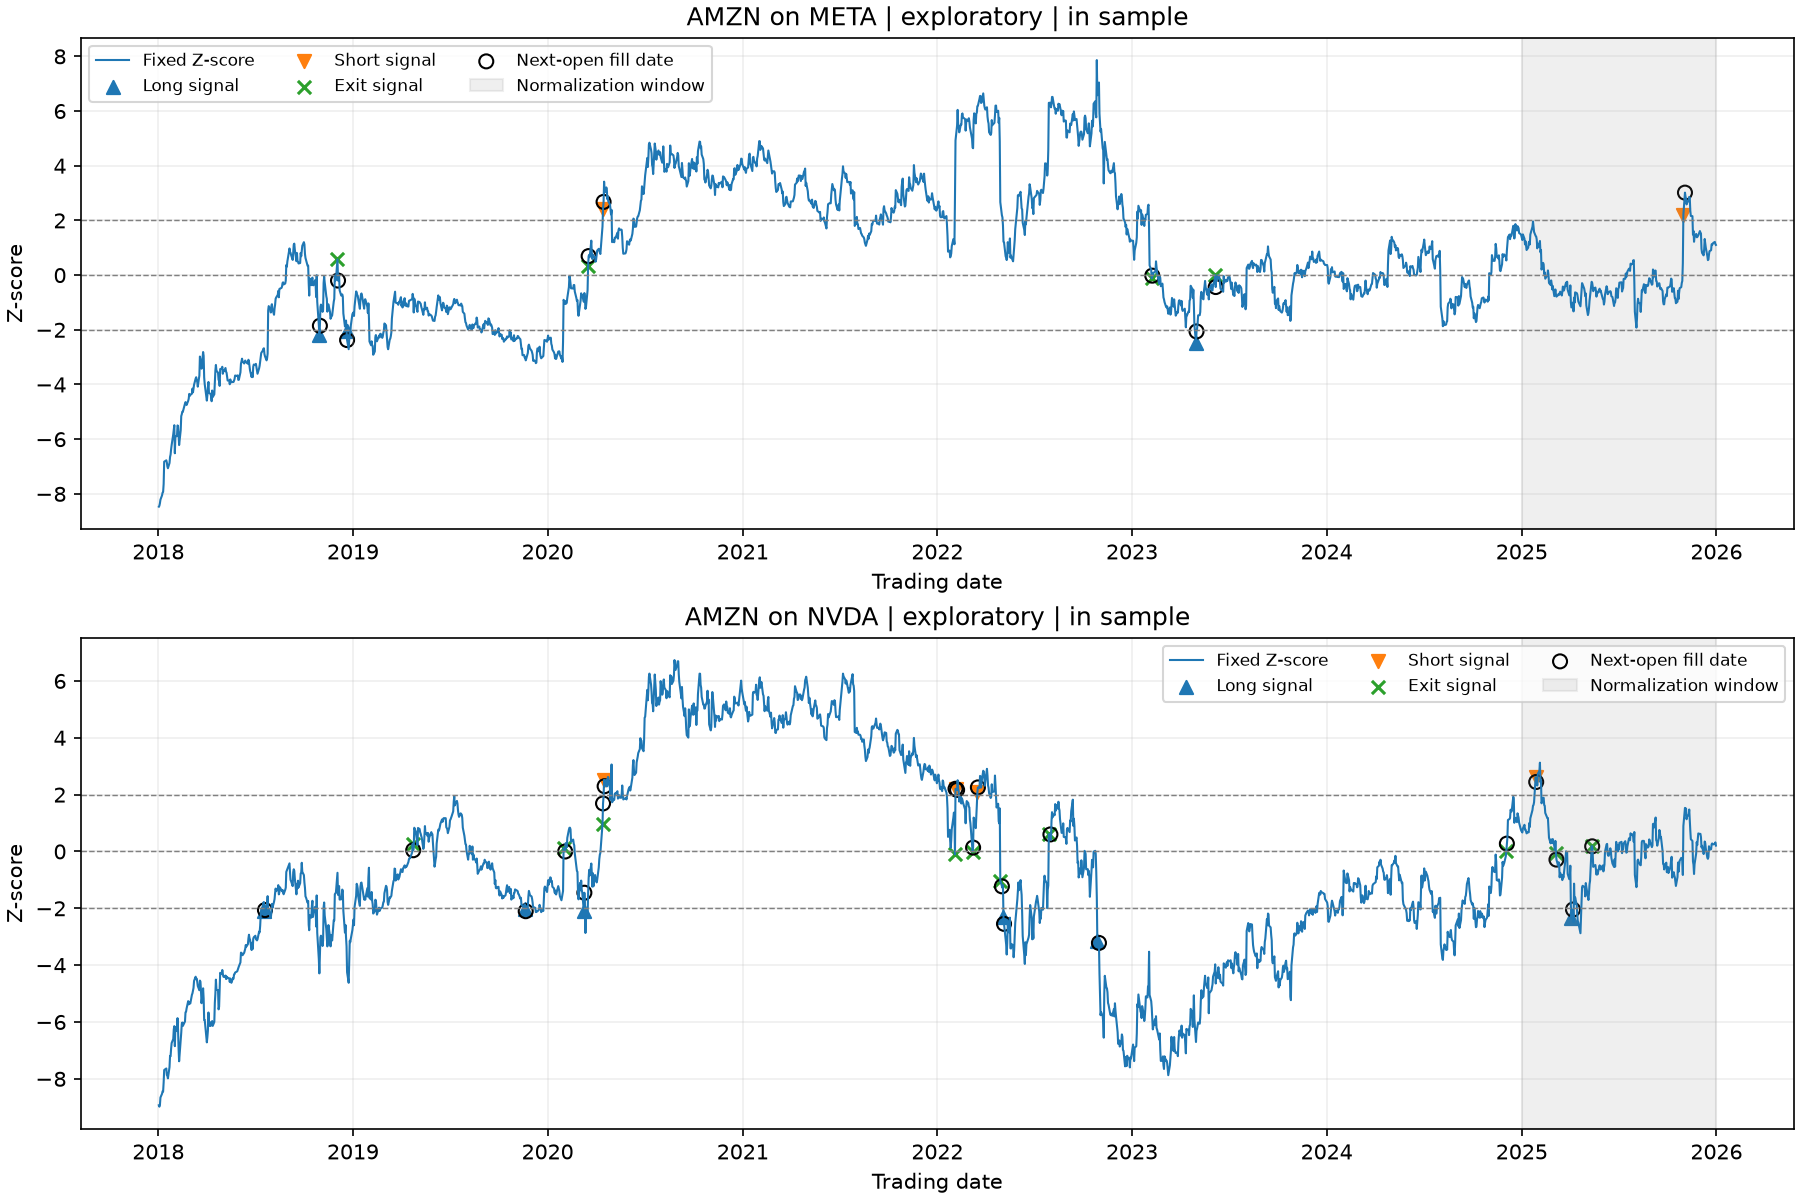

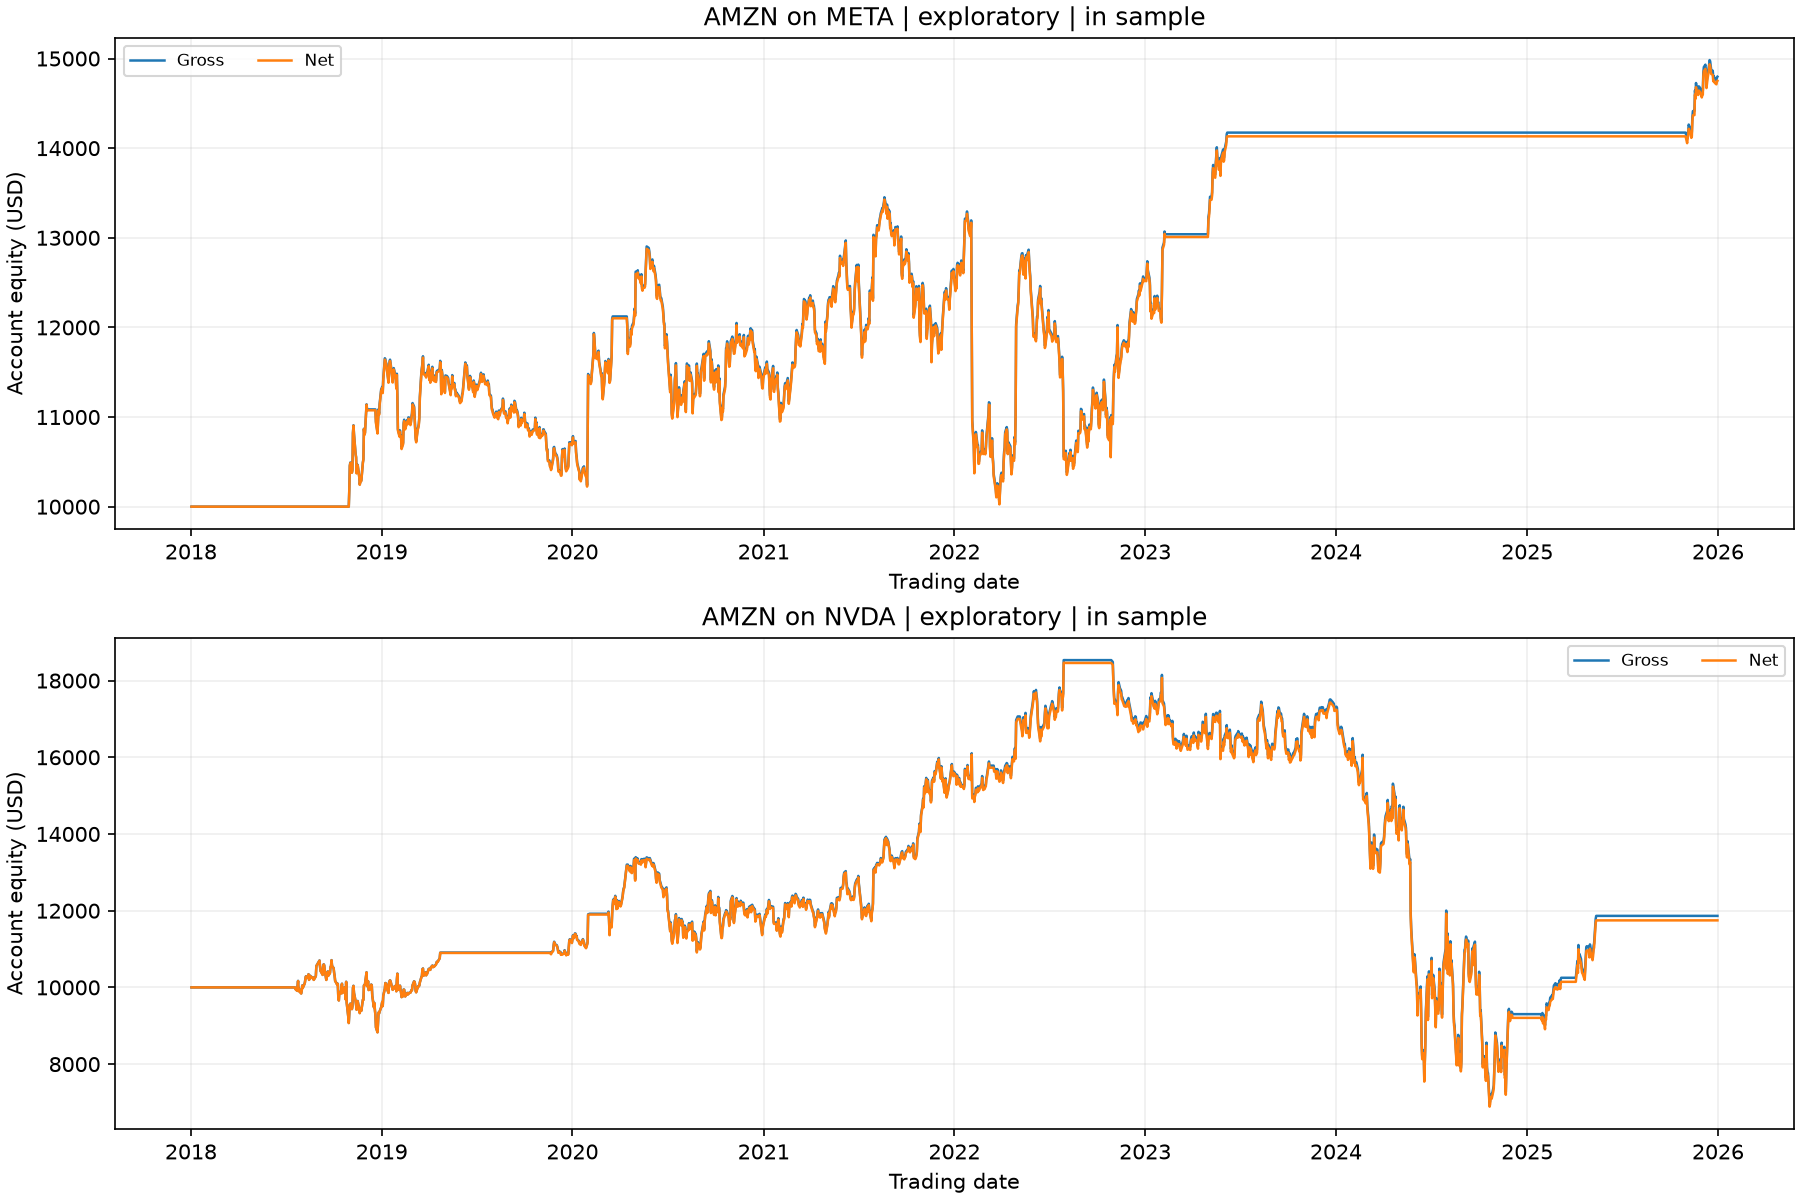

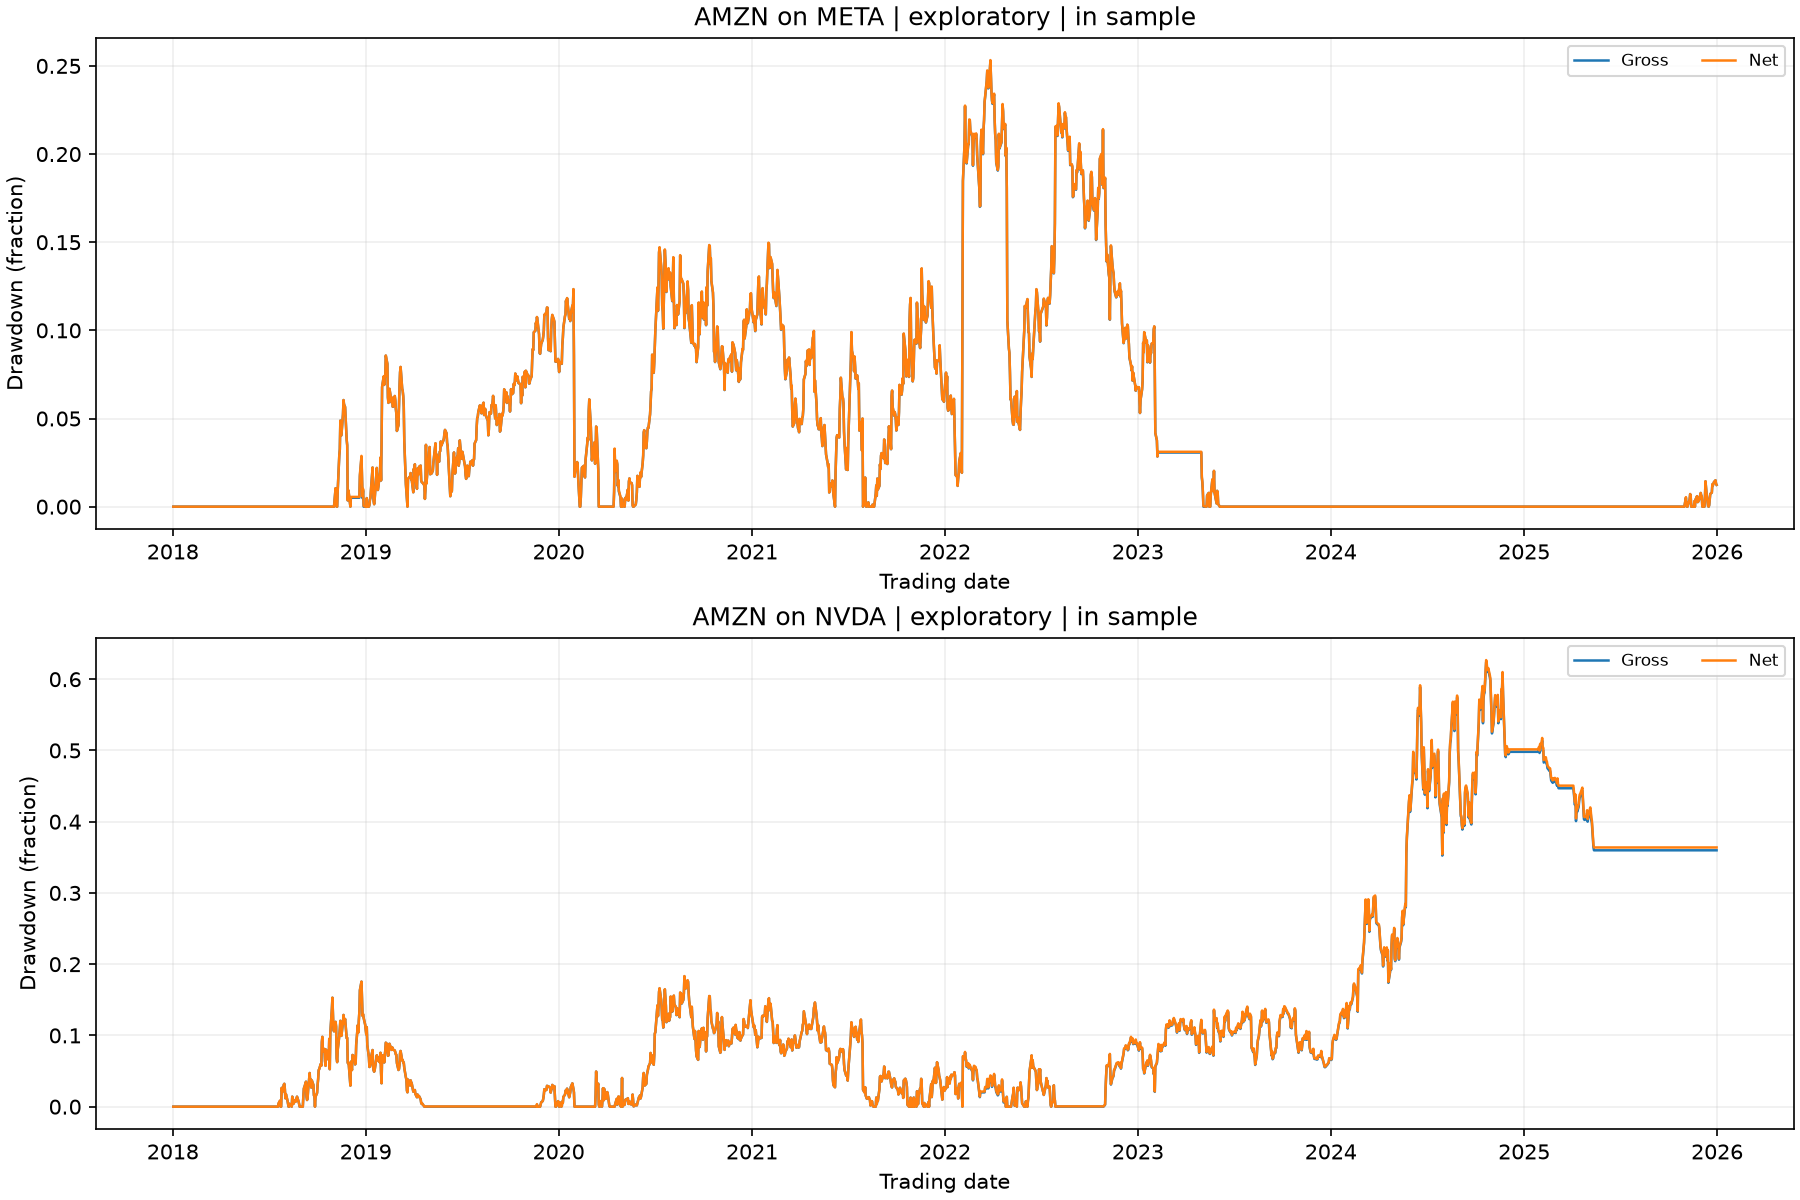

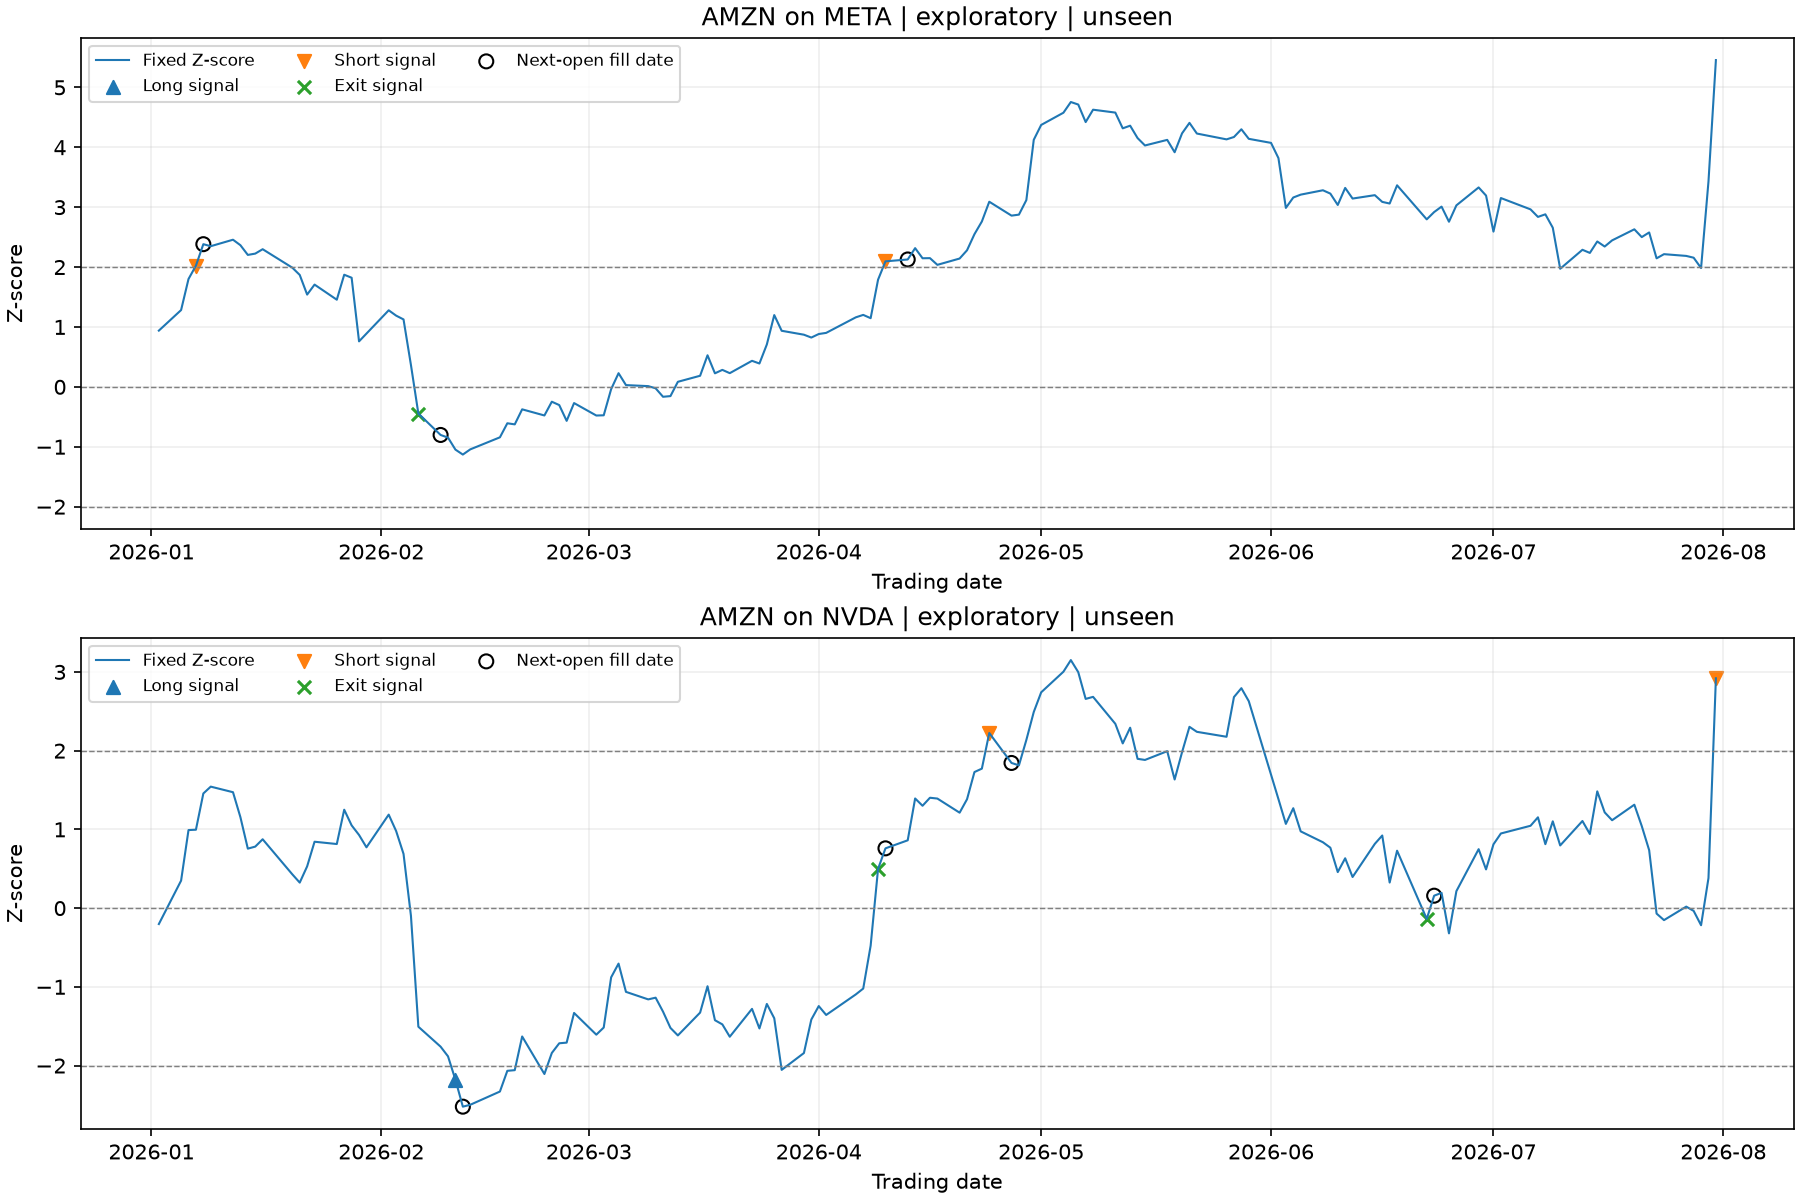

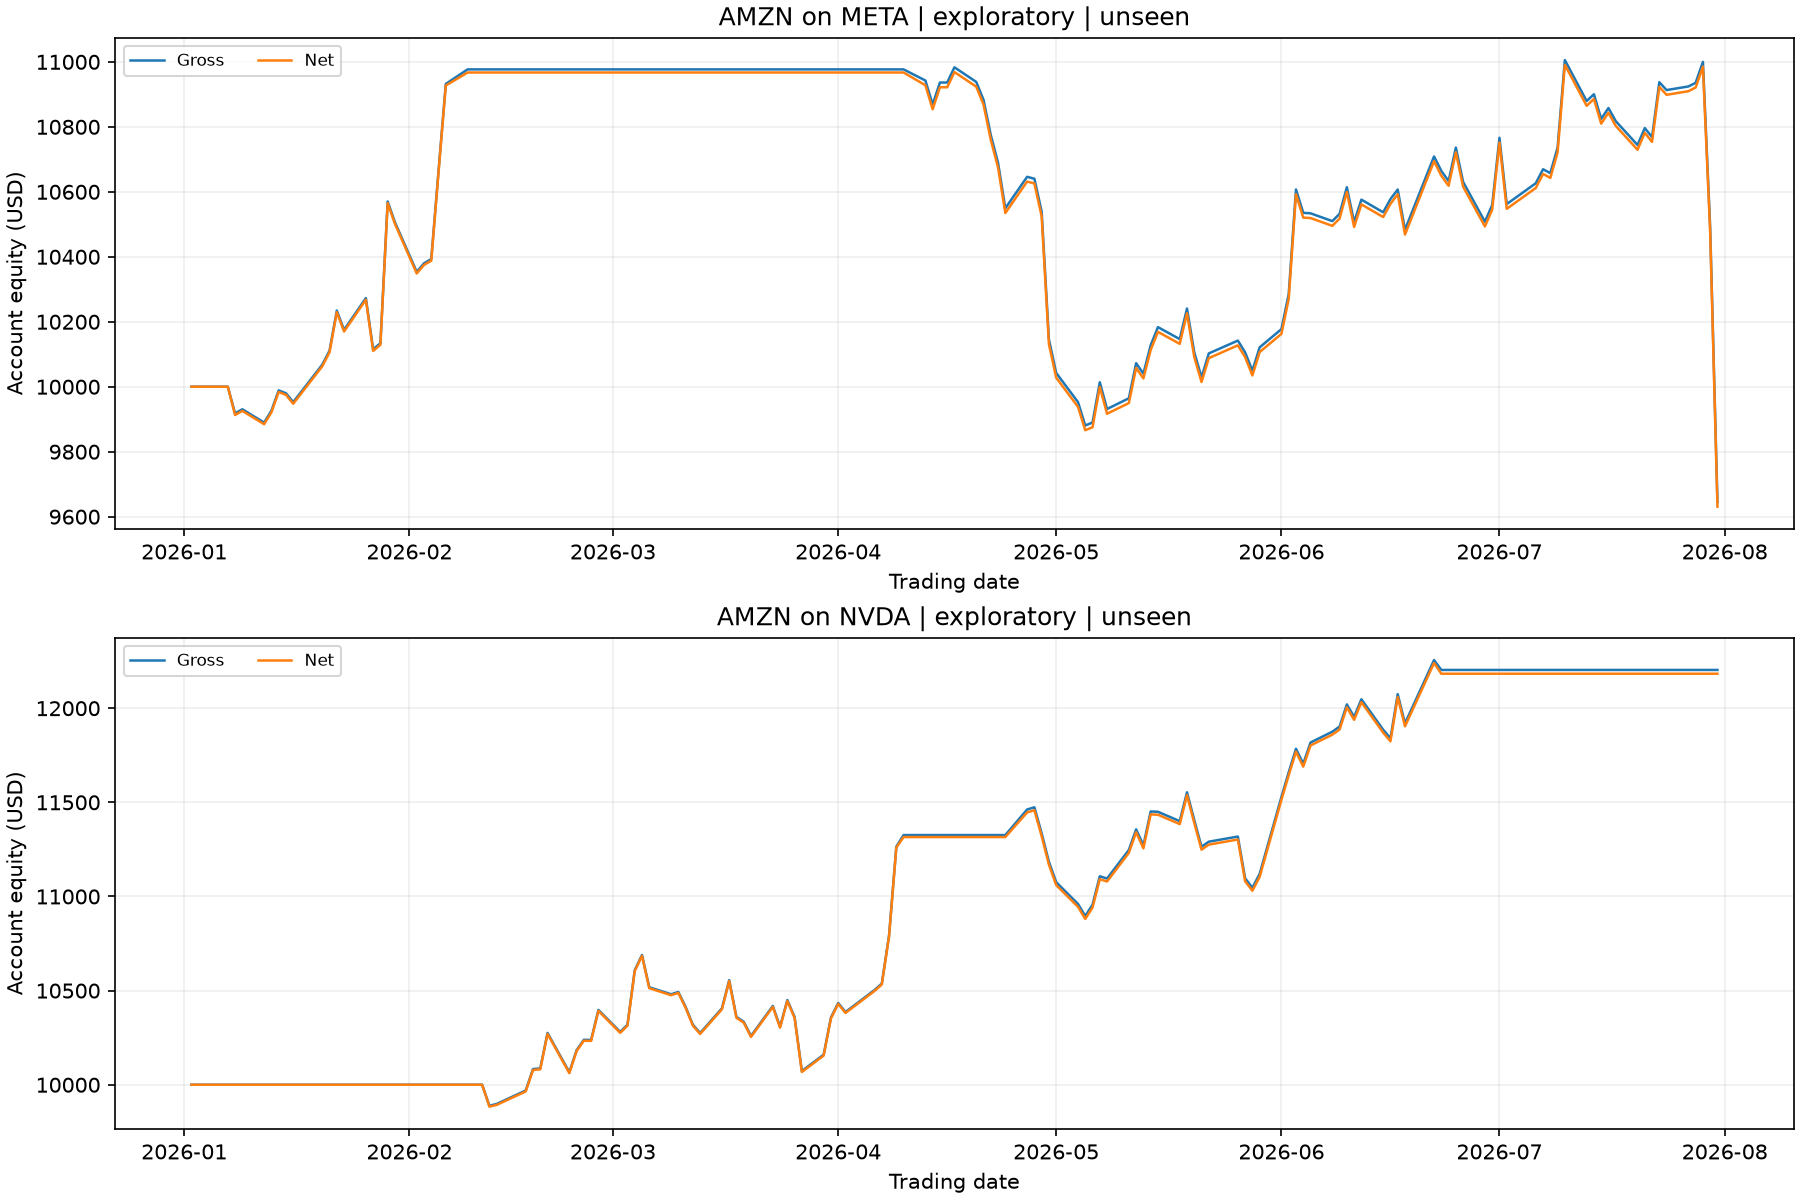

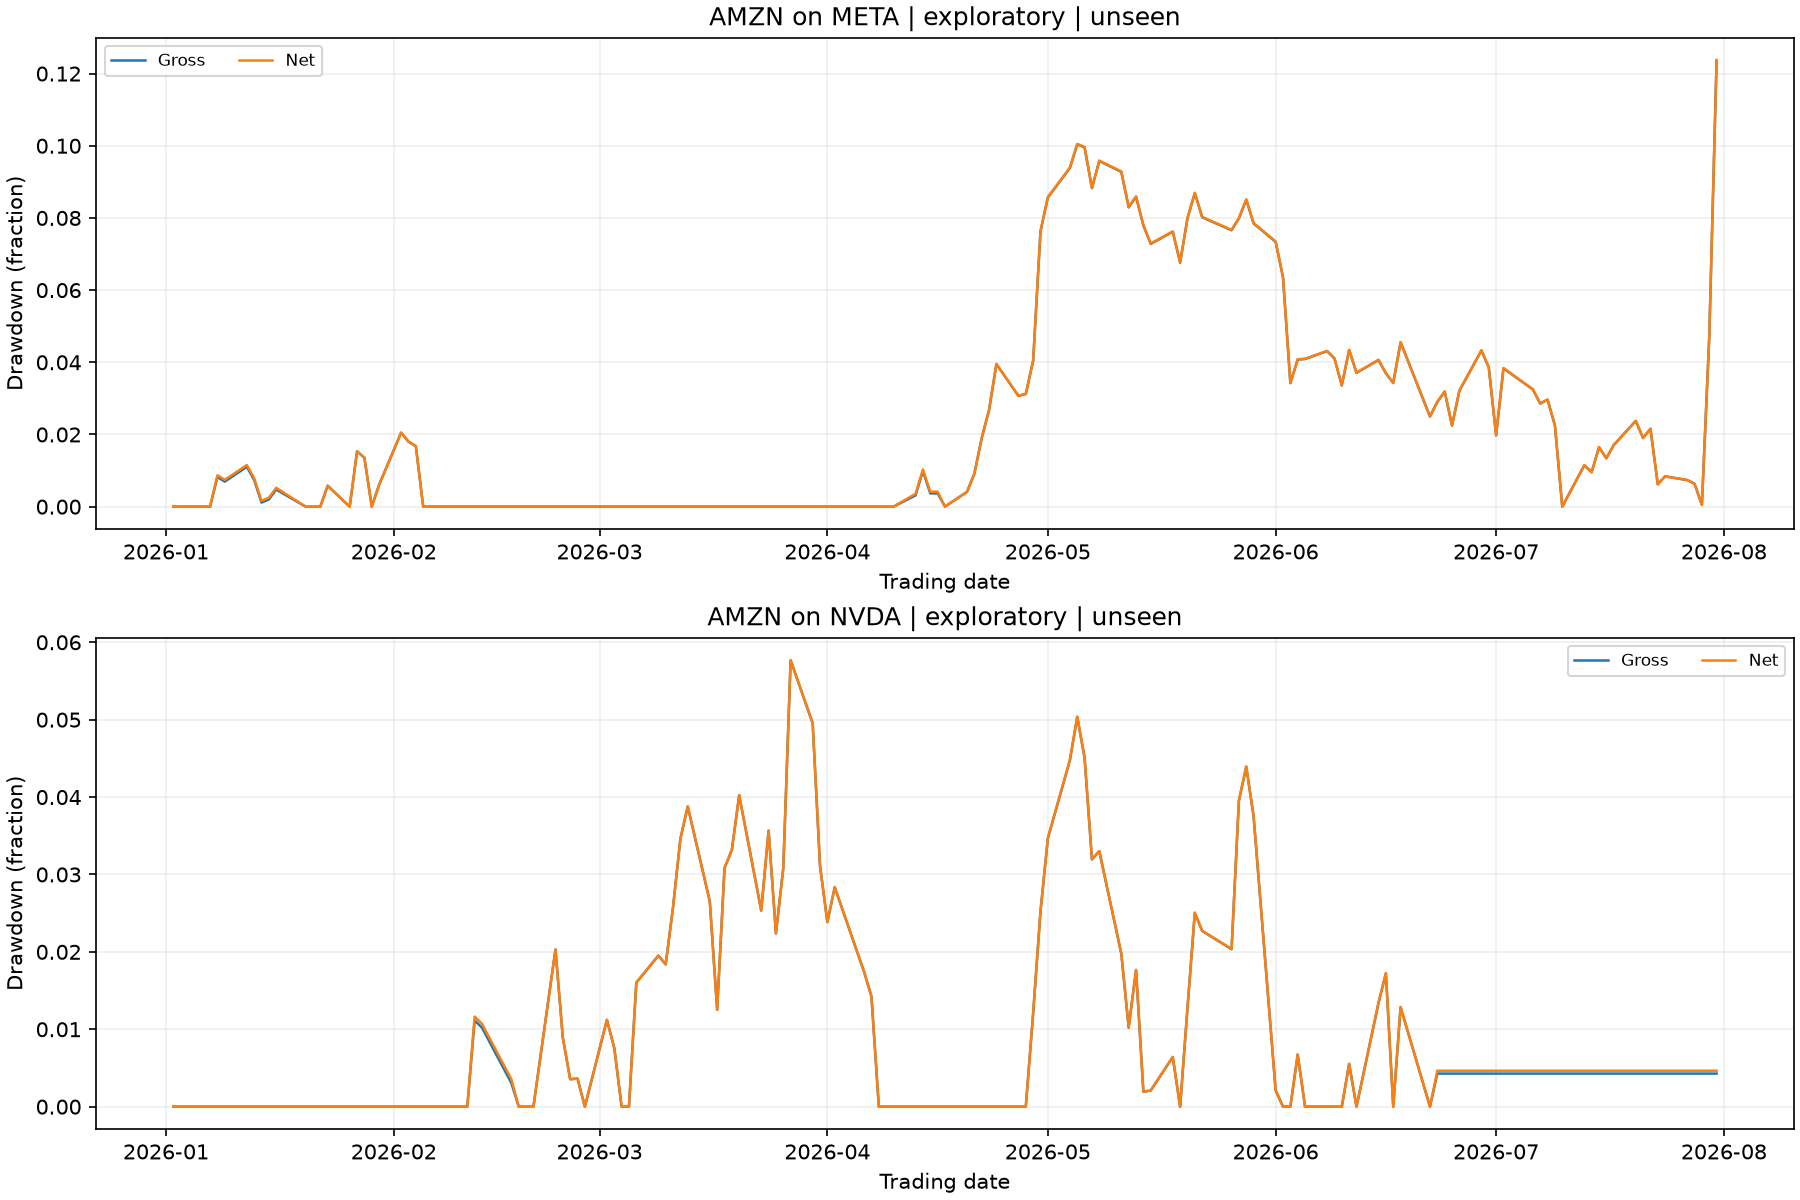

In [6]:
for period in runs:
    for kind in ["zscores", "equity", "drawdown"]:
        display(Image(filename=str(root / cfg["outputs"]["figures"] / period / f"{kind}.png")))

## How much came from the market

The beta-weighted holdings are not market-neutral. I estimate the market's share of each unseen trade from the 2018-2025 S&P 500 betas saved in Phase 2 and the S&P 500 move between the entry and exit signal closes (the endpoint close for an open trade). This reads the unseen S&P 500 only to describe trades that were already fixed. It is a single-factor estimate, not an exact attribution.

In [7]:
betas = pd.read_csv(root / "outputs/metrics/eda/benchmark_sensitivity.csv")
betas = betas[betas["period"] == "2018-2025"].set_index("stock")["beta"]
sp500 = pd.read_csv(root / cfg["unseen"], usecols=["Date", "GSPC_Close"], parse_dates=["Date"]).set_index("Date")["GSPC_Close"]
ledger = pd.read_csv(root / cfg["outputs"]["backtests"] / "unseen/trades.csv")
rows = []
for t in ledger.itertuples():
    pair = next(p for p in cfg["pairs"] if p["pair_id"] == t.pair_id)
    end = t.exit_signal_date if isinstance(t.exit_signal_date, str) else str(sp500.index[-1].date())
    move = sp500[end] / sp500[t.entry_signal_date] - 1
    exposure = (t.q_dependent * t.entry_dependent * betas[pair["dependent"]]
                + t.q_independent * t.entry_independent * betas[pair["independent"]])
    rows.append({"pair_id": t.pair_id, "trade_id": t.trade_id, "direction": t.direction, "status": t.status,
                 "window_start": t.entry_signal_date, "window_end": end, "sp500_return": move,
                 "market_beta_exposure": exposure, "market_part": exposure * move,
                 "gross_pnl": t.dependent_pnl + t.independent_pnl,
                 "dependent": pair["dependent"], "independent": pair["independent"],
                 "evidence_label": pair["evidence_label"], "period": "unseen", "model_version": cfg["model_version"]})
market = pd.DataFrame(rows)
market.to_csv(root / cfg["outputs"]["metrics"] / "unseen/market_exposure.csv", index=False,
              float_format="%.17g", lineterminator="\n")
display(market)

,pair_id,trade_id,direction,status,window_start,window_end,sp500_return,market_beta_exposure,market_part,gross_pnl,dependent,independent,evidence_label,period,model_version
0,AMZN_META,T0001,-1,closed,2026-01-07,2026-02-06,0.001643,-2424.780355,-3.983403,976.793352,AMZN,META,exploratory,unseen,phase4_v1
1,AMZN_META,T0002,-1,open,2026-04-10,2026-07-31,0.098700,-2424.780355,-239.326896,-1331.361705,AMZN,META,exploratory,unseen,phase4_v1
2,NVDA_AMZN,T0001,1,closed,2026-02-11,2026-04-09,-0.016828,5975.899584,-100.561575,1326.202168,AMZN,NVDA,exploratory,unseen,phase4_v1
3,NVDA_AMZN,T0002,-1,closed,2026-04-24,2026-06-22,0.042946,-5975.899584,-256.639676,877.024559,AMZN,NVDA,exploratory,unseen,phase4_v1


## Reproduction and limitations

The next cell reruns the standalone calculations and checks numeric output hashes. The independent validation also rebuilds equity from saved stock-leg fills and source prices. Both shortlisted pairs contain AMZN, so I report them separately. The backtest assumes full fills, fractional shares, and short availability. It omits dividends, borrowing costs, financing, cash interest, and broker margin rules. With few unseen trades, returns and win rates are descriptions of this interval. The Phase 3 exploratory labels still apply. Detailed findings are in `docs/phase_planning/phase_4_analysis.md`.

In [8]:
first_hashes = {period: metadata["outputs"] for period, metadata in runs.items()}
repeated = run_statistical_baseline(config_path)
assert first_hashes == {period: metadata["outputs"] for period, metadata in repeated.items()}
for metadata in repeated.values():
    for relative, expected in metadata["outputs"].items():
        assert sha256(root / relative) == expected
print("All saved numeric and fitted-artifact hashes agree on repeat execution.")

All saved numeric and fitted-artifact hashes agree on repeat execution.
